# Завдання 2. Вплив α і t на локальність і ранжування; зіставлення двох моделей

**Пункт 2 ТЗ.** Встановити вплив параметра перезапуску α і часу дифузії t на локальність розподілу і на порядок ранжування вузлів. Визначити, за яких співвідношень α і t дискретна та неперервна моделі дають близьке ранжування.

Обидві моделі — суми Σ_k w_k·s·P^k з різними вагами довжин блукань:
- PPR: w_k = α(1 − α)^k (геометричний розподіл, середнє (1 − α)/α, дисперсія (1 − α)/α²);
- теплове ядро: w_k = e^(−t)·t^k/k! (пуассонівський розподіл, середнє t, дисперсія t).

**Гіпотези для зіставлення α ↔ t:**
- **H1** — рівні середні довжини блукання: t = (1 − α)/α (основна гіпотеза);
- **H2** — рівна вага нульової довжини (маса, що лишається у вузлі запиту): e^(−t) = α, тобто t = −ln α;
- **H3** — рівне відношення ваг сусідніх довжин w_{r+1}/w_r на типовій відстані r вузлів верхньої частини ранжування: 1 − α = t/(r + 1), тобто t = (1 − α)(r + 1).

При однаковому середньому L геометричний розподіл має дисперсію L(L + 1), а пуассонівський — L. Тобто PPR і «локальніший» (більше ваги на k = 0), і має важчий хвіст. Через це H1 може виконуватися лише наближено.

**Тривіальний збіг.** При малих α і великих t обидві моделі прямують до d/Σd і тому «близькі» незалежно від зіставлення. Цю область визначаємо явно і робимо висновки про t*(α) лише поза нею.

**Графи:** ER, WS (p = 0.01), BA, SBM (p_out = 0.002), MetaQA. Цикл C₁₀₀ — контрольний приклад: він вершинно-транзитивний і симетричний відносно запиту, тому обидві моделі ранжують за відстанню, і близькість має бути ≈ 1 на всій сітці. Ланцюжок не вершинно-транзитивний, тож тривіальним прикладом не є. Окремо його не беремо, бо одновимірна структура вже детально вивчена в п. 1.

In [1]:
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

from reldiff.api import rank
from reldiff import graphs as G
from reldiff import metaqa as MQ

FIG = Path("../figures"); RES = Path("../results")
rng = np.random.default_rng(0)

GR = {
    "ER": G.erdos_renyi(1000, 0.01, seed=1),
    "WS p=0.01": G.watts_strogatz(1000, 10, 0.01, seed=2),
    "BA": G.barabasi_albert(1000, 5, seed=5),
    "SBM p_out=0.002": G.sbm([500, 500], 0.02, 0.002, seed=7),
}
g_mq, q_mq, _ = MQ.load_processed("../data/metaqa", 500, 0)
GR["MetaQA"] = g_mq
GR["цикл C₁₀₀ (контроль)"] = G.cycle(100)

# ті самі 20 запитів, що в п. 1 (та сама послідовність генератора для цих графів)
SEEDS = {}
_rng_p1 = np.random.default_rng(0)
_p1_order = ["ER", "WS p=0.01", "WS p=0.1", "WS p=1", "BA", "SBM p_out=0.0005", "SBM p_out=0.002",
             "SBM p_out=0.01", "ланцюжок P₁₀₀", "цикл C₁₀₀", "MetaQA"]
_p1_n = {"ланцюжок P₁₀₀": 100, "цикл C₁₀₀": 100}
for name in _p1_order:
    if name == "MetaQA":
        g = GR["MetaQA"]
        movies = sorted({t for t in q_mq.topic if "movie" in g.nodes[t]["kinds"]})
        people = sorted({t for t in q_mq.topic if {"actor", "director", "writer"} & set(g.nodes[t]["kinds"])
                         and "movie" not in g.nodes[t]["kinds"]})
        sel = list(_rng_p1.choice(movies, 10, replace=False)) + list(_rng_p1.choice(people, 10, replace=False))
    else:
        n = _p1_n.get(name, 1000)
        sel = list(_rng_p1.choice(n, 20, replace=False))
    key = "цикл C₁₀₀ (контроль)" if name == "цикл C₁₀₀" else name
    if key in GR:
        SEEDS[key] = sel

ALPHAS = np.logspace(np.log10(0.01), np.log10(0.9), 15)
TS = np.logspace(np.log10(0.05), np.log10(150), 30)
K_SMALL, K_BIG = 10, 50
print("α:", np.round(ALPHAS, 4))
print("t:", np.round(TS, 3))
print("H1 для α = 0.01:", (1 - 0.01) / 0.01, "≤ max t =", TS.max())

α: [0.01   0.0138 0.019  0.0262 0.0362 0.0499 0.0688 0.0949 0.1308 0.1804
 0.2488 0.3431 0.4732 0.6526 0.9   ]
t: [5.00000e-02 6.60000e-02 8.70000e-02 1.14000e-01 1.51000e-01 1.99000e-01
 2.62000e-01 3.45000e-01 4.55000e-01 6.00000e-01 7.91000e-01 1.04200e+00
 1.37300e+00 1.81000e+00 2.38600e+00 3.14400e+00 4.14400e+00 5.46100e+00
 7.19800e+00 9.48600e+00 1.25020e+01 1.64770e+01 2.17160e+01 2.86210e+01
 3.77210e+01 4.97150e+01 6.55220e+01 8.63550e+01 1.13813e+02 1.50000e+02]
H1 для α = 0.01: 99.0 ≤ max t = 150.00000000000003


In [2]:
RESOLVE = 1e-10   # оцінки < 1e-10·max вважаємо нерозрізненими (нижче точності обчислення: експоненту
                  # і лінійну систему рахуємо з абсолютною похибкою ~1e-16, тож порядок там — шум)

def prep(scores, exclude):
    # оцінки без вузла запиту, нормовані на максимум; нерозрізнені → 0; округлення до 12 цифр,
    # щоб справжні нічиї (симетричні вузли) лишалися нічиями
    x = scores.drop(index=exclude).to_numpy(dtype=float)
    x = x / np.abs(x).max()
    x[x < RESOLVE] = 0.0
    return np.round(x, 12)

def topk(x, k):
    # топ-k серед розрізнених вузлів (оцінка > 0), з нічиїми на межі: усі вузли з оцінкою ≥ k-ї;
    # якщо розрізнених вузлів менше за k — усі розрізнені
    pos = np.flatnonzero(x > 0)
    if pos.size <= k:
        return set(pos)
    thr = np.sort(x[pos])[::-1][k - 1]
    return set(np.flatnonzero(x >= thr))

def overlap(a, b, k):
    A, B = topk(a, k), topk(b, k)
    return len(A & B) / min(len(A), len(B))

N_CMP = []
def tau_union(a, b, k):
    # τ_b на вузлах об'єднання топ-k, які розрізняють обидві моделі
    U = [i for i in sorted(topk(a, k) | topk(b, k)) if a[i] > 0 and b[i] > 0]
    N_CMP.append(len(U))
    if len(U) < 3:
        return np.nan
    t = kendalltau(a[U], b[U]).statistic
    return 1.0 if np.isnan(t) else t

def tau_with_distance(x, dist, k):
    T = sorted(topk(x, k))
    t = kendalltau(x[T], -dist[T]).statistic
    return np.nan if np.isnan(t) else t

# Обчислення: для кожного графа і запиту — оцінки PPR на сітці α і теплового ядра на сітці t
DATA = {}
for name, g in GR.items():
    nodes = list(g.nodes())
    deg = rank(g, nodes[0], "ppr", return_info=True)[1]["degrees"]
    per_seed = []
    for q in SEEDS[name]:
        q = nodes[q] if not isinstance(q, str) else q
        d = nx.single_source_shortest_path_length(g, q)
        dist = np.array([d.get(v, np.inf) for v in nodes if v != q], dtype=float)
        P = [prep(rank(g, q, "ppr", alpha=a), q) for a in ALPHAS]
        H = [prep(rank(g, q, "heat", t=t), q) for t in TS]
        D = prep(deg, q)
        per_seed.append(dict(q=q, dist=dist, P=P, H=H, D=D))
    DATA[name] = per_seed
    print(f"{name}: {len(per_seed)} запитів пораховано")

ER: 20 запитів пораховано


WS p=0.01: 20 запитів пораховано


BA: 20 запитів пораховано


SBM p_out=0.002: 20 запитів пораховано


MetaQA: 20 запитів пораховано


цикл C₁₀₀ (контроль): 20 запитів пораховано


## Завдання 2.1. Локальність розподілу залежно від α і t

Метрики (середнє за 20 запитами):
- маса у вузлі запиту;
- маса в радіусі r ≤ 2;
- середня відстань маси d̄;
- ефективна кількість вузлів exp(H).

Окремо дві міри зв'язку ранжування з граничними випадками:
- τ_b між оцінками і −відстанню на топ-50 моделі (локальна межа α → 1);
- перетин топ-50 з ранжуванням за степенем (глобальна межа d/Σd, α → 0).

Вісь абсцис спільна — середня довжина блукання: L = (1 − α)/α для PPR і t для теплового ядра. Якщо H1 точна, криві двох моделей мають збігатися.

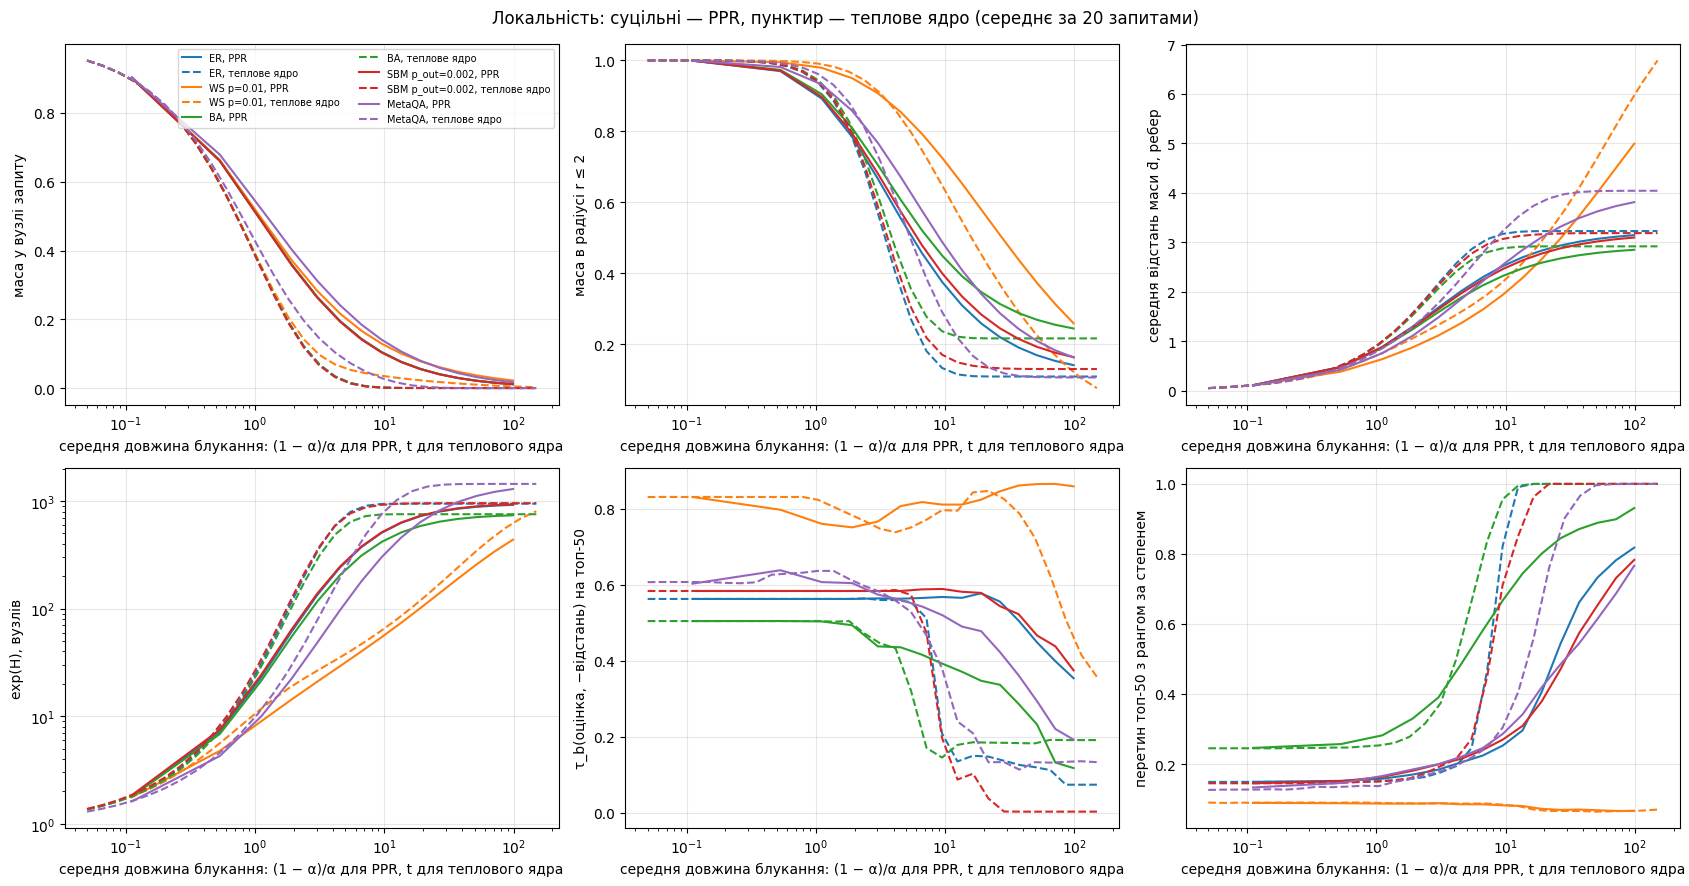

L =  1.00: теоретична вага k = 0: PPR α = 0.5000, теплове ядро e^(−L) = 3.68e-01
L =  5.67: теоретична вага k = 0: PPR α = 0.1499, теплове ядро e^(−L) = 3.45e-03
L = 19.00: теоретична вага k = 0: PPR α = 0.0500, теплове ядро e^(−L) = 5.60e-09


In [3]:
def locality(scores, q, dist_full):
    x = scores.to_numpy(dtype=float)
    p = x[x > 0]
    fin = np.isfinite(dist_full)
    return dict(маса_у_запиті=scores[q], маса_r_до_2=x[dist_full <= 2].sum(),
                сер_відстань=(x[fin] * dist_full[fin]).sum(), eff_вузлів=np.exp(-(p * np.log(p)).sum()))

rows = []
for name, g in GR.items():
    nodes = list(g.nodes())
    for item in DATA[name]:
        q = item["q"]
        d = nx.single_source_shortest_path_length(g, q)
        dist_full = np.array([d.get(v, np.inf) for v in nodes], dtype=float)
        for a, Pa in zip(ALPHAS, item["P"]):
            rows.append(dict(граф=name, модель="PPR", параметр=a, L=(1 - a) / a,
                             **locality(rank(g, q, "ppr", alpha=a), q, dist_full),
                             τ_з_відстанню=tau_with_distance(Pa, item["dist"], K_BIG),
                             перетин_зі_степенем=overlap(Pa, item["D"], K_BIG)))
        for t, Ht in zip(TS, item["H"]):
            rows.append(dict(граф=name, модель="теплове ядро", параметр=t, L=t,
                             **locality(rank(g, q, "heat", t=t), q, dist_full),
                             τ_з_відстанню=tau_with_distance(Ht, item["dist"], K_BIG),
                             перетин_зі_степенем=overlap(Ht, item["D"], K_BIG)))
loc = pd.DataFrame(rows)
loc_mean = loc.groupby(["граф", "модель", "параметр"], sort=False).mean(numeric_only=True).reset_index()
loc_mean.to_csv(RES / "02_lokalnist.csv", index=False)

metrics = [("маса_у_запиті", "маса у вузлі запиту"), ("маса_r_до_2", "маса в радіусі r ≤ 2"),
           ("сер_відстань", "середня відстань маси d̄, ребер"), ("eff_вузлів", "exp(H), вузлів"),
           ("τ_з_відстанню", "τ_b(оцінка, −відстань) на топ-50"), ("перетин_зі_степенем", "перетин топ-50 з рангом за степенем")]
names = [n for n in GR if "контроль" not in n]
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, lab) in zip(axs.ravel(), metrics):
    for i, name in enumerate(names):
        for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
            sub = loc_mean[(loc_mean["граф"] == name) & (loc_mean["модель"] == model)].sort_values("L")
            ax.plot(sub["L"], sub[col], ls, color=f"C{i}", lw=1.5, label=f"{name}, {model}")
    ax.set_xscale("log"); ax.set_xlabel("середня довжина блукання: (1 − α)/α для PPR, t для теплового ядра")
    ax.set_ylabel(lab); ax.grid(alpha=0.3)
    if col == "eff_вузлів": ax.set_yscale("log")
axs[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle("Локальність: суцільні — PPR, пунктир — теплове ядро (середнє за 20 запитами)")
plt.tight_layout(); plt.savefig(FIG / "02_lokalnist.png", dpi=200); plt.show()

# при однаковій середній довжині блукання PPR лишає у вузлі запиту більше маси (вага k = 0: α проти e^(−t))
for L in (1.0, 5.67, 19.0):
    a = 1 / (1 + L)
    print(f"L = {L:5.2f}: теоретична вага k = 0: PPR α = {a:.4f}, теплове ядро e^(−L) = {np.exp(-L):.2e}")

Порівняння при **рівно однаковій** середній довжині блукання: для кожного α із сітки теплове ядро рахуємо окремо при t = (1 − α)/α (не найближча точка сітки t).

In [4]:
rows = []
for name, g in GR.items():
    nodes = list(g.nodes())
    for q in [nodes[q] if not isinstance(q, str) else q for q in SEEDS[name]]:
        d = nx.single_source_shortest_path_length(g, q)
        dist_full = np.array([d.get(v, np.inf) for v in nodes], dtype=float)
        for a in ALPHAS:
            L = (1 - a) / a
            lp = locality(rank(g, q, "ppr", alpha=a), q, dist_full)
            lh = locality(rank(g, q, "heat", t=L), q, dist_full)
            rows.append(dict(граф=name, α=a, L=L, **{f"PPR: {k}": v for k, v in lp.items()},
                             **{f"heat: {k}": v for k, v in lh.items()}))
eqL = pd.DataFrame(rows).groupby(["граф", "α", "L"], sort=False).mean().reset_index()
eqL.to_csv(RES / "02_lokalnist_rivne_L.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format)
show = eqL[np.isin(np.round(eqL["α"], 4), np.round(ALPHAS[[5, 8, 12]], 4))]
display(show[["граф", "α", "L", "PPR: маса_у_запиті", "heat: маса_у_запиті", "PPR: маса_r_до_2", "heat: маса_r_до_2",
              "PPR: сер_відстань", "heat: сер_відстань", "PPR: eff_вузлів", "heat: eff_вузлів"]])
ctrl_free = eqL[~eqL["граф"].str.contains("контроль")]
print(f"Частка (граф, α), де PPR лишає у вузлі запиту більше маси, ніж теплове ядро при тій самій L: "
      f"{(ctrl_free['PPR: маса_у_запиті'] > ctrl_free['heat: маса_у_запиті']).mean():.3f}; "
      f"де ефективна кількість вузлів PPR менша: {(ctrl_free['PPR: eff_вузлів'] < ctrl_free['heat: eff_вузлів']).mean():.3f}")

,граф,α,L,PPR: маса_у_запиті,heat: маса_у_запиті,PPR: маса_r_до_2,heat: маса_r_до_2,PPR: сер_відстань,heat: сер_відстань,PPR: eff_вузлів,heat: eff_вузлів
5,ER,0.050,19.047,0.056,0.001,0.259,0.109,2.833,3.226,725.552,946.859
8,ER,0.131,6.643,0.144,0.008,0.457,0.202,2.294,3.015,373.474,883.254
12,ER,0.473,1.113,0.488,0.350,0.892,0.927,0.886,0.996,22.917,30.728
20,WS p=0.01,0.050,19.047,0.079,0.023,0.580,0.454,2.659,3.022,101.372,119.371
23,WS p=0.01,0.131,6.643,0.167,0.046,0.793,0.747,1.637,1.876,40.014,46.790
27,WS p=0.01,0.473,1.113,0.494,0.355,0.979,0.989,0.637,0.761,8.950,11.719
35,BA,0.050,19.047,0.056,0.001,0.347,0.217,2.587,2.917,587.518,755.559
38,BA,0.131,6.643,0.143,0.008,0.521,0.296,2.127,2.764,311.298,709.730
42,BA,0.473,1.113,0.487,0.349,0.905,0.936,0.863,0.984,21.273,28.812
50,SBM p_out=0.002,0.050,19.047,0.056,0.001,0.284,0.136,2.773,3.164,731.995,954.720


Частка (граф, α), де PPR лишає у вузлі запиту більше маси, ніж теплове ядро при тій самій L: 1.000; де ефективна кількість вузлів PPR менша: 1.000


## Завдання 2.2. Як змінюється порядок ранжування

- τ_b (на об'єднанні топ-50) між ранжуваннями при сусідніх значеннях параметра: показує, де ранжування найчутливіше до α або t.
- Перетин топ-10 з еталонами PPR(α = 0.15) і heat(t = 5.67), тобто з тією самою моделлю при «типовому» значенні.

Еталони: α = 0.1308, t = 5.461


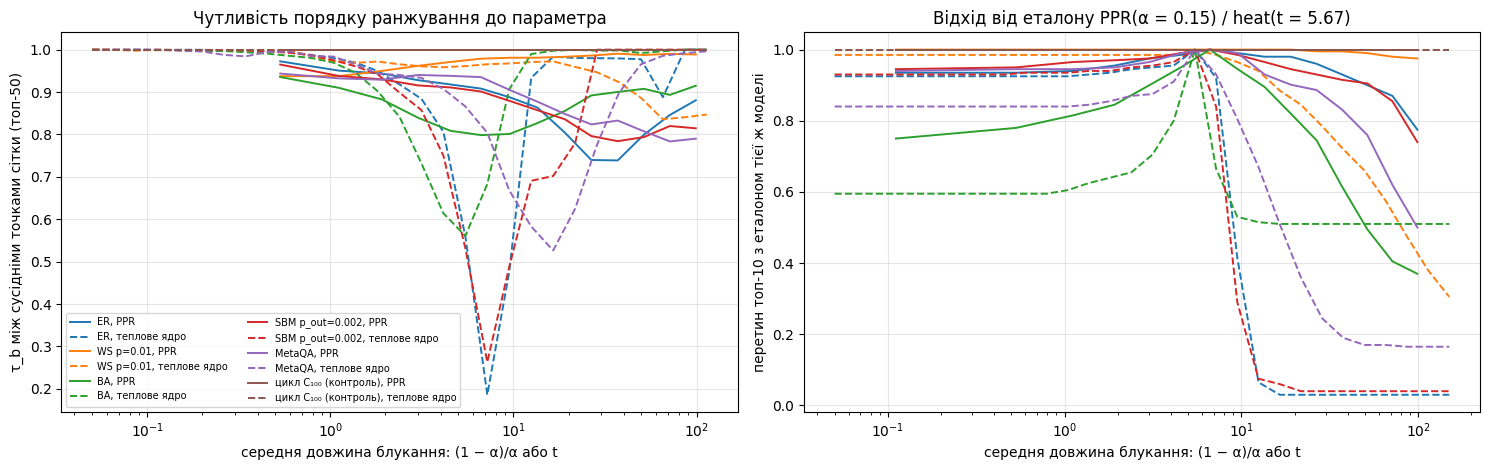

In [5]:
i_ref_a = np.argmin(np.abs(ALPHAS - 0.15)); i_ref_t = np.argmin(np.abs(TS - 5.67))
print(f"Еталони: α = {ALPHAS[i_ref_a]:.4f}, t = {TS[i_ref_t]:.3f}")
rows = []
for name in GR:
    for item in DATA[name]:
        for i in range(len(ALPHAS)):
            rows.append(dict(граф=name, модель="PPR", параметр=ALPHAS[i], L=(1 - ALPHAS[i]) / ALPHAS[i],
                             τ_з_сусіднім=tau_union(item["P"][i], item["P"][i + 1], K_BIG) if i + 1 < len(ALPHAS) else np.nan,
                             перетин10_з_еталоном=overlap(item["P"][i], item["P"][i_ref_a], K_SMALL)))
        for i in range(len(TS)):
            rows.append(dict(граф=name, модель="теплове ядро", параметр=TS[i], L=TS[i],
                             τ_з_сусіднім=tau_union(item["H"][i], item["H"][i + 1], K_BIG) if i + 1 < len(TS) else np.nan,
                             перетин10_з_еталоном=overlap(item["H"][i], item["H"][i_ref_t], K_SMALL)))
sens = pd.DataFrame(rows).groupby(["граф", "модель", "параметр"], sort=False).mean(numeric_only=True).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for i, name in enumerate(GR):
    for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
        sub = sens[(sens["граф"] == name) & (sens["модель"] == model)].sort_values("L")
        axs[0].plot(sub["L"], sub["τ_з_сусіднім"], ls, color=f"C{i}", lw=1.4, label=f"{name}, {model}")
        axs[1].plot(sub["L"], sub["перетин10_з_еталоном"], ls, color=f"C{i}", lw=1.4)
axs[0].set_ylabel("τ_b між сусідніми точками сітки (топ-50)")
axs[0].set_title("Чутливість порядку ранжування до параметра")
axs[1].set_ylabel("перетин топ-10 з еталоном тієї ж моделі")
axs[1].set_title("Відхід від еталону PPR(α = 0.15) / heat(t = 5.67)")
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("середня довжина блукання: (1 − α)/α або t"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "02_chutlyvist_ranzhuvannya.png", dpi=200); plt.show()

## Завдання 2.3. Близькість двох моделей на сітці (α, t)

Для кожної пари (α, t) і кожного запиту рахуємо близькість ранжувань PPR(α) і heat(t): перетин топ-10, перетин топ-50 і τ_b на об'єднанні топ-50. Беремо середнє за 20 запитами.

Оцінки, менші за 10⁻¹⁰ від максимуму, вважаємо нерозрізненими: їхній порядок визначають похибки округлення. Так буває в теплового ядра при малих t для віддалених вузлів. Такі вузли не входять у топ-k, а τ_b рахуємо лише на вузлах, які розрізняють обидві моделі; розмір цієї множини наведено в таблицях.

**Тривіальна область:** точки, де і PPR(α), і heat(t) мають перетин топ-50 з ранжуванням за степенем > 0.8. На карті вона заштрихована. Емпіричний оптимум t*(α) = argmax_t τ_b(PPR(α), heat(t)) і перевірку H1–H3 робимо лише для тих α, для яких PPR(α) ще поза тривіальною областю (перетин зі степенем ≤ 0.8).

Для H3 типова відстань r — середня відстань топ-10 вузлів PPR(α) від запиту (середнє за запитами).

In [6]:
TRIV = 0.8
MAPS, rows_opt = {}, []
for name in GR:
    S = {m: np.zeros((len(ALPHAS), len(TS))) for m in ("o10", "o50", "tau", "ncmp")}
    degP = np.zeros(len(ALPHAS)); degH = np.zeros(len(TS)); r_top = np.zeros(len(ALPHAS))
    for item in DATA[name]:
        # якщо всі степені однакові (регулярний граф, напр. цикл), ранжування за степенем — суцільна
        # нічия і не несе інформації: тривіальна область не визначена (NaN → не позначаємо)
        deg_ok = np.ptp(item["D"]) > 0
        for i, Pa in enumerate(item["P"]):
            degP[i] += overlap(Pa, item["D"], K_BIG) if deg_ok else np.nan
            T10 = sorted(topk(Pa, K_SMALL)); r_top[i] += np.mean(item["dist"][T10])
            for j, Ht in enumerate(item["H"]):
                S["o10"][i, j] += overlap(Pa, Ht, K_SMALL)
                S["o50"][i, j] += overlap(Pa, Ht, K_BIG)
                S["tau"][i, j] += tau_union(Pa, Ht, K_BIG); S["ncmp"][i, j] += N_CMP[-1]
        for j, Ht in enumerate(item["H"]):
            degH[j] += overlap(Ht, item["D"], K_BIG) if deg_ok else np.nan
    ns = len(DATA[name])
    S = {m: v / ns for m, v in S.items()}; degP /= ns; degH /= ns; r_top /= ns
    triv = (degP[:, None] > TRIV) & (degH[None, :] > TRIV)
    MAPS[name] = dict(S=S, degP=degP, degH=degH, triv=triv, r_top=r_top)
    for i, a in enumerate(ALPHAS):
        j = int(np.argmax(S["tau"][i]))
        jH1 = int(np.argmin(np.abs(np.log(TS) - np.log((1 - a) / a))))
        rows_opt.append(dict(граф=name, α=a, PPR_перетин_зі_степенем=degP[i], поза_тривіальною=degP[i] <= TRIV,
                             t_опт=TS[j], τ_макс=S["tau"][i, j], вузлів_у_τ=S["ncmp"][i, j], перетин10_при_t_опт=S["o10"][i, j],
                             t_H1=(1 - a) / a, τ_при_H1=S["tau"][i, jH1], перетин10_при_H1=S["o10"][i, jH1],
                             t_H2=-np.log(a), t_H3=(1 - a) * (r_top[i] + 1), r_топ10=r_top[i],
                             ширина_гребеня_τ_0_95=(TS[S["tau"][i] >= 0.95 * S["tau"][i, j]].min(),
                                                    TS[S["tau"][i] >= 0.95 * S["tau"][i, j]].max())))
opt = pd.DataFrame(rows_opt)
opt.to_csv(RES / "02_t_optimum.csv", index=False)
long = [dict(граф=n, α=a, t=t, перетин10=M["S"]["o10"][i, j], перетин50=M["S"]["o50"][i, j], τ=M["S"]["tau"][i, j],
             вузлів_у_τ=M["S"]["ncmp"][i, j],
             тривіальна=M["triv"][i, j]) for n, M in MAPS.items() for i, a in enumerate(ALPHAS) for j, t in enumerate(TS)]
pd.DataFrame(long).to_csv(RES / "02_karta_alpha_t.csv", index=False)

ctrl = MAPS["цикл C₁₀₀ (контроль)"]["S"]
print(f"КОНТРОЛЬ (цикл C₁₀₀): мін. перетин топ-10 = {ctrl['o10'].min():.6f}, мін. перетин топ-50 = {ctrl['o50'].min():.6f}, "
      f"мін. τ_b = {ctrl['tau'].min():.6f} на всій сітці {len(ALPHAS)}×{len(TS)}")
for name, M in MAPS.items():
    print(f"  {name:22s}: вузлів у порівнянні τ_b — мін. {M['S']['ncmp'].min():.1f}, медіана {np.median(M['S']['ncmp']):.1f}")

КОНТРОЛЬ (цикл C₁₀₀): мін. перетин топ-10 = 1.000000, мін. перетин топ-50 = 1.000000, мін. τ_b = 1.000000 на всій сітці 15×30
  ER                    : вузлів у порівнянні τ_b — мін. 50.0, медіана 69.9
  WS p=0.01             : вузлів у порівнянні τ_b — мін. 50.0, медіана 57.7
  BA                    : вузлів у порівнянні τ_b — мін. 50.0, медіана 67.1
  SBM p_out=0.002       : вузлів у порівнянні τ_b — мін. 50.0, медіана 69.1
  MetaQA                : вузлів у порівнянні τ_b — мін. 50.5, медіана 65.4
  цикл C₁₀₀ (контроль)  : вузлів у порівнянні τ_b — мін. 10.0, медіана 24.0


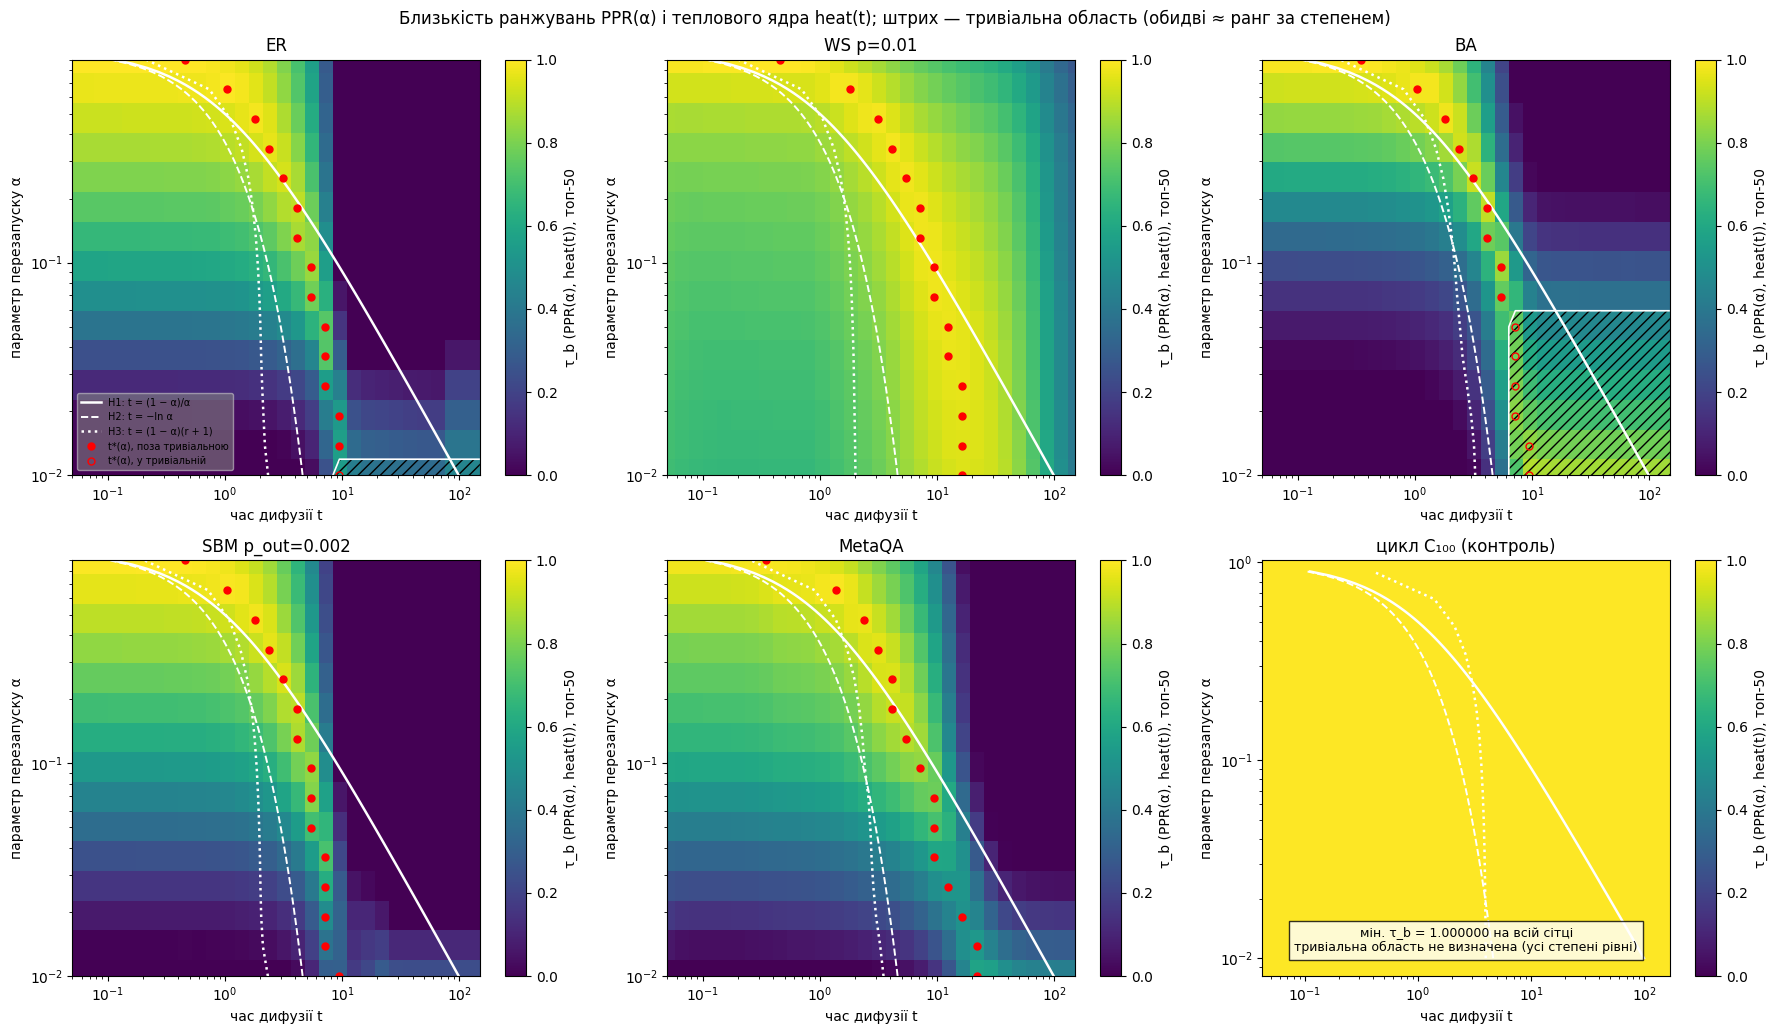

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10.5))
al = np.logspace(-2, np.log10(0.9), 100)
for ax, name in zip(axs.ravel(), GR):
    M = MAPS[name]
    im = ax.pcolormesh(TS, ALPHAS, M["S"]["tau"], shading="nearest", cmap="viridis", vmin=0, vmax=1)
    ax.contourf(TS, ALPHAS, M["triv"].astype(float), levels=[0.5, 1.5], colors="none", hatches=["///"])
    ax.contour(TS, ALPHAS, M["triv"].astype(float), levels=[0.5], colors="white", linewidths=1.2)
    ax.plot((1 - al) / al, al, "w-", lw=1.8, label="H1: t = (1 − α)/α")
    ax.plot(-np.log(al), al, "w--", lw=1.4, label="H2: t = −ln α")
    ax.plot((1 - ALPHAS) * (M["r_top"] + 1), ALPHAS, "w:", lw=1.8, label="H3: t = (1 − α)(r + 1)")
    sub = opt[opt["граф"] == name]
    ok = sub["поза_тривіальною"]
    if "контроль" in name:
        ax.text(0.5, 0.06, f"мін. τ_b = {M['S']['tau'].min():.6f} на всій сітці\nтривіальна область не визначена (усі степені рівні)",
                transform=ax.transAxes, ha="center", color="black", fontsize=9, bbox=dict(fc="white", alpha=0.8))
        ax.set_title(name); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("час дифузії t"); ax.set_ylabel("параметр перезапуску α")
        fig.colorbar(im, ax=ax, label="τ_b (PPR(α), heat(t)), топ-50")
        continue
    ax.plot(sub["t_опт"][ok], sub["α"][ok], "o", color="red", ms=5, label="t*(α), поза тривіальною")
    ax.plot(sub["t_опт"][~ok], sub["α"][~ok], "o", mfc="none", color="red", ms=5, label="t*(α), у тривіальній")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(TS.min(), TS.max()); ax.set_ylim(ALPHAS.min(), ALPHAS.max())
    ax.set_xlabel("час дифузії t"); ax.set_ylabel("параметр перезапуску α"); ax.set_title(name)
    fig.colorbar(im, ax=ax, label="τ_b (PPR(α), heat(t)), топ-50")
axs[0, 0].legend(fontsize=7, loc="lower left", facecolor="gray", framealpha=0.6)
fig.suptitle("Близькість ранжувань PPR(α) і теплового ядра heat(t); штрих — тривіальна область (обидві ≈ ранг за степенем)")
plt.tight_layout(); plt.savefig(FIG / "02_karta_alpha_t.png", dpi=200); plt.show()

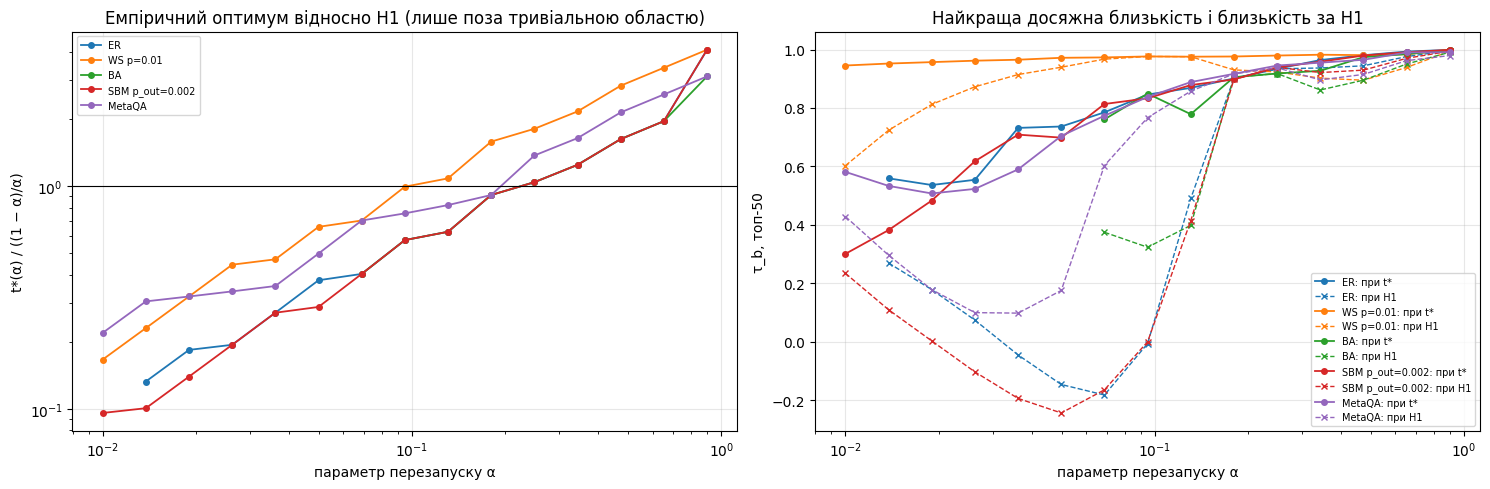

Середнє |ln(t*/t_H)| поза тривіальною областю (менше = краща гіпотеза):


,|log t*/t_H1|,|log t*/t_H2|,|log t*/t_H3|
граф,,,
BA,0.509,0.859,0.595
ER,0.892,0.858,0.951
MetaQA,0.750,1.198,1.060
SBM p_out=0.002,1.045,0.793,0.951
WS p=0.01,0.822,1.382,1.579


Усього: H1 0.828, H2 1.034, H3 1.066 (точок 68)
Втрата τ_b через зіставлення за H1 замість t*: медіана 0.069, максимум 0.978


,граф,α,t_опт,t_H1,t_H2,t_H3,τ_макс,τ_при_H1,перетин10_при_t_опт,ширина_гребеня_τ_0_95
1,ER,0.014,9.486,71.512,4.284,2.194,0.559,0.270,0.505,"(9.486017681947514, 9.486017681947514)"
2,ER,0.019,9.486,51.580,3.962,2.134,0.536,0.179,0.470,"(9.486017681947514, 9.486017681947514)"
3,ER,0.026,7.198,37.127,3.641,2.079,0.554,0.074,0.890,"(7.197525246644808, 7.197525246644808)"
4,ER,0.036,7.198,26.647,3.320,2.038,0.732,-0.045,0.910,"(7.197525246644808, 7.197525246644808)"
5,ER,0.050,7.198,19.047,2.998,2.009,0.737,-0.146,0.915,"(7.197525246644808, 7.197525246644808)"
...,...,...,...,...,...,...,...,...,...,...
70,MetaQA,0.249,4.144,3.019,1.391,1.972,0.945,0.938,0.975,"(3.143988857168359, 4.143637273776524)"
71,MetaQA,0.343,3.144,1.914,1.070,1.712,0.955,0.896,0.990,"(2.385504637810609, 4.143637273776524)"
72,MetaQA,0.473,2.386,1.113,0.748,1.370,0.965,0.915,0.990,"(1.3733423079837939, 2.385504637810609)"
73,MetaQA,0.653,1.373,0.532,0.427,0.902,0.990,0.962,1.000,"(0.3453624645072629, 1.8100039903262277)"



Тривіальна область (PPR(α) має перетин топ-50 зі степенем > 0.8):
  ER              : α ≤ 0.0100 (1 з 15), t ≥ 9.49; макс. перетин PPR зі степенем 0.818, heat — 1.000
  WS p=0.01       : α ≤ nan (0 з 15), t ≥ nan; макс. перетин PPR зі степенем 0.089, heat — 0.090
  BA              : α ≤ 0.0499 (6 з 15), t ≥ 7.20; макс. перетин PPR зі степенем 0.931, heat — 1.000
  SBM p_out=0.002 : α ≤ nan (0 з 15), t ≥ 12.50; макс. перетин PPR зі степенем 0.783, heat — 1.000
  MetaQA          : α ≤ nan (0 з 15), t ≥ 28.62; макс. перетин PPR зі степенем 0.766, heat — 1.000


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for i, name in enumerate([n for n in GR if "контроль" not in n]):
    sub = opt[(opt["граф"] == name) & opt["поза_тривіальною"]]
    axs[0].plot(sub["α"], sub["t_опт"] / sub["t_H1"], "o-", color=f"C{i}", ms=4, lw=1.3, label=name)
    axs[1].plot(sub["α"], sub["τ_макс"], "o-", color=f"C{i}", ms=4, lw=1.3, label=f"{name}: при t*")
    axs[1].plot(sub["α"], sub["τ_при_H1"], "x--", color=f"C{i}", ms=5, lw=1.0, label=f"{name}: при H1")
axs[0].axhline(1, color="k", lw=0.8)
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_xlabel("параметр перезапуску α"); axs[0].set_ylabel("t*(α) / ((1 − α)/α)")
axs[0].set_title("Емпіричний оптимум відносно H1 (лише поза тривіальною областю)")
axs[1].set_xscale("log"); axs[1].set_xlabel("параметр перезапуску α"); axs[1].set_ylabel("τ_b, топ-50")
axs[1].set_title("Найкраща досяжна близькість і близькість за H1")
for ax in axs: ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "02_t_optimum.png", dpi=200); plt.show()

nt = opt[opt["поза_тривіальною"] & ~opt["граф"].str.contains("контроль")].copy()
for h in ("t_H1", "t_H2", "t_H3"):
    nt[f"|log t*/{h}|"] = np.abs(np.log(nt["t_опт"] / nt[h]))
pd.set_option("display.float_format", "{:.3f}".format)
print("Середнє |ln(t*/t_H)| поза тривіальною областю (менше = краща гіпотеза):")
display(nt.groupby("граф")[["|log t*/t_H1|", "|log t*/t_H2|", "|log t*/t_H3|"]].mean())
print(f"Усього: H1 {nt['|log t*/t_H1|'].mean():.3f}, H2 {nt['|log t*/t_H2|'].mean():.3f}, H3 {nt['|log t*/t_H3|'].mean():.3f} "
      f"(точок {len(nt)})")
print(f"Втрата τ_b через зіставлення за H1 замість t*: медіана {np.median(nt['τ_макс'] - nt['τ_при_H1']):.3f}, "
      f"максимум {np.max(nt['τ_макс'] - nt['τ_при_H1']):.3f}")
display(nt[["граф", "α", "t_опт", "t_H1", "t_H2", "t_H3", "τ_макс", "τ_при_H1", "перетин10_при_t_опт", "ширина_гребеня_τ_0_95"]])

tr = opt[~opt["поза_тривіальною"] & ~opt["граф"].str.contains("контроль")]
print("\nТривіальна область (PPR(α) має перетин топ-50 зі степенем > 0.8):")
for name in [n for n in GR if "контроль" not in n]:
    a_tr = opt[(opt["граф"] == name) & ~opt["поза_тривіальною"]]["α"]
    t_tr = TS[MAPS[name]["degH"] > TRIV]
    print(f"  {name:16s}: α ≤ {a_tr.max() if len(a_tr) else float('nan'):.4f} ({len(a_tr)} з {len(ALPHAS)}), "
          f"t ≥ {t_tr.min() if len(t_tr) else float('nan'):.2f}; макс. перетин PPR зі степенем {MAPS[name]['degP'].max():.3f}, "
          f"heat — {MAPS[name]['degH'].max():.3f}")

### Чутливість висновків про t*(α) до порогу тривіальної області

Поріг θ визначає лише те, які α потрапляють у перевірку гіпотез: t*(α) шукаємо по всій сітці t, тож порогом він не обрізаний. Але на ER t* при малих α (9.486) збігся з першою точкою сітки, де перетин теплового ядра зі ступеневим ранжуванням > 0.8. Тому перевіряємо дві речі:
1. **Чи оптимум — артефакт грубої сітки.** Рахуємо t* на дрібній сітці (60 точок від 2 до 50) для α < 0.1 і порівнюємо з моментом t_θ, коли середній перетин heat(t) зі ступеневим ранжуванням перетинає поріг θ ∈ {0.7, 0.8, 0.9}.
2. **Як від θ залежать висновки щодо H1–H3:** які α потрапляють у перевірку і чому дорівнює середнє |ln(t*/t_H)| за смугами α.

In [9]:
TF = np.logspace(np.log10(2), np.log10(50), 60)
SMALL_A = ALPHAS[ALPHAS < 0.1]
fine_rows = []
for name in [n for n in GR if "контроль" not in n]:
    g = GR[name]; nodes = list(g.nodes())
    deg = rank(g, nodes[0], "ppr", return_info=True)[1]["degrees"]
    tau = np.zeros((len(SMALL_A), len(TF))); dH = np.zeros(len(TF))
    for item in DATA[name]:
        q = item["q"]
        Hf = [prep(rank(g, q, "heat", t=t), q) for t in TF]
        dH += np.array([overlap(h, item["D"], K_BIG) for h in Hf])
        for i, a in enumerate(SMALL_A):
            Pa = item["P"][int(np.argmin(np.abs(ALPHAS - a)))]
            tau[i] += np.array([tau_union(Pa, h, K_BIG) for h in Hf])
    tau /= len(DATA[name]); dH /= len(DATA[name])
    t_theta = {th: (TF[np.argmax(dH > th)] if np.any(dH > th) else np.nan) for th in (0.7, 0.8, 0.9)}
    for i, a in enumerate(SMALL_A):
        j = int(np.argmax(tau[i]))
        fine_rows.append(dict(граф=name, α=a, t_опт_дрібна=TF[j], τ_макс_дрібна=tau[i, j],
                              t_опт_груба=opt[(opt["граф"] == name) & np.isclose(opt["α"], a)]["t_опт"].item(),
                              t_θ07=t_theta[0.7], t_θ08=t_theta[0.8], t_θ09=t_theta[0.9],
                              heat_перетин_зі_степенем_при_t_опт=dH[j]))
fine = pd.DataFrame(fine_rows)
fine.to_csv(RES / "02_t_optimum_drібна_sitka.csv".replace("drібна", "dribna"), index=False)
pd.set_option("display.float_format", "{:.3f}".format)
display(fine.groupby("граф").agg(t_опт_дрібна_мін=("t_опт_дрібна", "min"), t_опт_дрібна_макс=("t_опт_дрібна", "max"),
                                 heat_перетин_при_t_опт=("heat_перетин_зі_степенем_при_t_опт", "mean"),
                                 t_θ07=("t_θ07", "first"), t_θ08=("t_θ08", "first"), t_θ09=("t_θ09", "first")))

rows = []
for th in (0.7, 0.8, 0.9):
    sub = opt[(opt["PPR_перетин_зі_степенем"] <= th) & ~opt["граф"].str.contains("контроль")].copy()
    for h in ("t_H1", "t_H2", "t_H3"):
        sub[h] = np.abs(np.log(sub["t_опт"] / sub[h]))
    sub["смуга"] = pd.cut(sub["α"], [0, 0.1, 0.3, 1], labels=["α<0.1", "0.1≤α<0.3", "α≥0.3"])
    excl = opt[(opt["PPR_перетин_зі_степенем"] > th) & ~opt["граф"].str.contains("контроль")]
    for band, gsub in sub.groupby("смуга", observed=True):
        rows.append(dict(поріг=th, смуга=band, точок=len(gsub), H1=gsub["t_H1"].mean(), H2=gsub["t_H2"].mean(),
                         H3=gsub["t_H3"].mean(), виключено_α=len(excl)))
sens_th = pd.DataFrame(rows)
sens_th.to_csv(RES / "02_chutlyvist_do_porogu.csv", index=False)
display(sens_th)
for th in (0.7, 0.8, 0.9):
    excl = opt[(opt["PPR_перетин_зі_степенем"] > th) & ~opt["граф"].str.contains("контроль")]
    print(f"θ = {th}: виключені (граф, α): {[(r.граф, round(r.α, 4)) for r in excl.itertuples()]}")

,t_опт_дрібна_мін,t_опт_дрібна_макс,heat_перетин_при_t_опт,t_θ07,t_θ08,t_θ09
граф,,,,,,
BA,5.340,8.725,0.812,5.955,7.014,8.262
ER,5.340,9.731,0.554,8.725,9.731,10.853
MetaQA,7.014,22.058,0.458,20.887,23.295,28.976
SBM p_out=0.002,5.056,8.262,0.430,9.731,10.853,14.256
WS p=0.01,8.262,17.733,0.076,NaN,NaN,NaN


,поріг,смуга,точок,H1,H2,H3,виключено_α
0,0.700,α<0.1,27,0.968,1.065,1.450,13
1,0.700,0.1≤α<0.3,15,0.237,0.951,0.886,13
2,0.700,α≥0.3,20,0.794,1.107,0.589,13
3,0.800,α<0.1,33,1.118,1.029,1.438,7
4,0.800,0.1≤α<0.3,15,0.237,0.951,0.886,7
5,0.800,α≥0.3,20,0.794,1.107,0.589,7
6,0.900,α<0.1,39,1.209,0.984,1.381,1
7,0.900,0.1≤α<0.3,15,0.237,0.951,0.886,1
8,0.900,α≥0.3,20,0.794,1.107,0.589,1


θ = 0.7: виключені (граф, α): [('ER', 0.01), ('ER', 0.0138), ('ER', 0.019), ('BA', 0.01), ('BA', 0.0138), ('BA', 0.019), ('BA', 0.0262), ('BA', 0.0362), ('BA', 0.0499), ('BA', 0.0688), ('SBM p_out=0.002', 0.01), ('SBM p_out=0.002', 0.0138), ('MetaQA', 0.01)]
θ = 0.8: виключені (граф, α): [('ER', 0.01), ('BA', 0.01), ('BA', 0.0138), ('BA', 0.019), ('BA', 0.0262), ('BA', 0.0362), ('BA', 0.0499)]
θ = 0.9: виключені (граф, α): [('BA', 0.01)]


## Висновки

1. **Локальність при рівно однаковій середній довжині блукання** (t = (1 − α)/α, усі 75 пар «граф, α»). PPR в усіх 100% випадків лишає більше маси у вузлі запиту, має меншу середню відстань маси й меншу ефективну кількість вузлів. Наприклад, на ER при L = 6.643: маса у запиті 0.144 проти 0.008, ефективна кількість вузлів 373 проти 883. Водночас при α ≥ 0.25 (28% пар) теплове ядро має більше маси в радіусі 2: на ER при α = 0.47 це 0.927 проти 0.892. Отже, PPR має і більший пік у запиті, і важчий хвіст, як і передбачає порівняння дисперсій L(L + 1) і L. Перехід до ранжування за степенем у теплового ядра різкий. У PPR він поступовий: навіть при α = 0.01 перетин топ-50 зі ступеневим ранжуванням лише 0.818 (ER), 0.783 (SBM), 0.766 (MetaQA).
2. **Тривіальна область** (поріг 0.8) невелика: на ER — α ≤ 0.01 і t ≥ 9.49, на BA — α ≤ 0.05 і t ≥ 7.20. На SBM і MetaQA її немає, бо PPR не досягає порогу, хоча теплове ядро досягає його при t ≥ 12.5 і t ≥ 28.6. На WS (p = 0.01) немає навіть для теплового ядра: перетин 0.090 при t = 150. Контроль на циклі C₁₀₀ дав τ_b = 1 і перетини = 1 на всій сітці 15 × 30. Тривіальна область там не визначена, бо всі степені однакові.
3. **H1 (t = (1 − α)/α) виконується лише в смузі 0.1 ≤ α < 0.3.** Там середнє |ln(t*/t_H1)| = 0.237 (t*/t_H1 від 0.62 до 1.81), і медіанна τ_b за H1 дорівнює найкращій досяжній, 0.917. При α < 0.1 t* росте зі зменшенням α значно повільніше за H1. На дрібній сітці при зміні α у 9.5 раза t* зростає лише в 1.6–3.1 раза: ER від 5.34 до 9.73, MetaQA від 7.0 до 22.1. За той самий час H1 зростає в ~10 разів, до 99. Тому ранжування за H1 майже не узгоджуються: медіанна τ_b 0.179, на SBM до −0.24, тоді як при t* — 0.737. При α ≥ 0.3 t* у 1.5–4 рази більше за H1, і найближча тут H3 (0.589 проти 0.794). Проте близькість висока при будь-якому розумному t: медіана τ_b 0.983 при t* і 0.941 при H1.
4. **Чутливість до порогу тривіальної області θ ∈ {0.7, 0.8, 0.9}.**
   - Для α ≥ 0.1 висновки від θ не залежать: жодне таке α не виключається, H1 = 0.237 у середній смузі, H3 = 0.589 при α ≥ 0.3.
   - При α < 0.1 у перевірку потрапляє 27, 33 або 39 точок. Найкраща гіпотеза перемикається між H1 (0.968 при θ = 0.7) і H2 (1.029 і 0.984 при θ = 0.8 і 0.9). Але всі три помиляються в середньому приблизно в e разів, тож висновок «при α < 0.1 жодна з гіпотез не працює» стійкий до θ.
   - Збіг t* = 9.486 з межею тривіальної області на ER — це один і той самий вузол грубої сітки, тобто артефакт. На дрібній сітці для α = 0.014…0.095 t* = 5.34…9.21, а перетин heat(t*) зі ступеневим ранжуванням лише 0.24–0.78, нижче за поріг. Лише при α = 0.01 (яке на ER саме в тривіальній області) t* = 9.73 = t_θ=0.8.
5. **Практичний висновок.** При α ≥ 0.18 і t = (1 − α)/α обидві моделі дають близьке ранжування на всіх п'яти графах: τ_b на топ-50 від 0.862 (BA, α = 0.34) до 0.997, медіана 0.932. Уже при α = 0.13 зіставлення за H1 на ER, SBM і BA дає лише 0.40–0.49. При α < 0.1 моделі якісно різні, і зіставлення за середньою довжиною блукання вводить в оману. При найменшому α оптимальне t* наближається до моменту, коли теплове ядро стає ранжуванням за степенем: перетин heat(t*) з ним при α = 0.01 становить 0.58 (SBM), 0.77 (MetaQA), 0.85 (ER), 0.93 (BA).